# 01 · Exploratory Data Analysis & Data Preparation

**Goal:** understand the Telco customer dataset, check its quality (missing values,
duplicates, outliers), study distributions and correlations, and prepare the features
(encoding, scaling, feature engineering) used by the clustering and classification notebooks.

| Step | Content |
| --- | --- |
| 1 | Load the data |
| 2 | Data quality: types, missing values, duplicates |
| 3 | Target variable `Churn` |
| 4 | Numeric distributions |
| 5 | Outliers |
| 6 | Categorical variables vs churn |
| 7 | Correlations |
| 8 | Feature engineering |
| 9 | Encoding & scaling |
| 10 | Save the prepared dataset |

## Setup
Imports, paths and constants. The notebook is self-contained: the only input is the raw CSV.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = ROOT / "data" / "raw" / "wa-fn-usec-telco-customer.csv"
PROCESSED_DATA = ROOT / "data" / "processed" / "telco_clean.csv"

RANDOM_STATE = 42
TARGET = "Churn"
ID_COLUMN = "customerID"
RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
RAW_BINARY = ["SeniorCitizen"]
RAW_CATEGORICAL = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                   "PaperlessBilling", "PaymentMethod"]

## 1. Load the data
The raw dataset is the IBM Telco Customer Churn file: one row per customer.

In [2]:
raw = pd.read_csv(RAW_DATA)
print("Shape:", raw.shape)
raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Available columns vs. the project brief.** The brief lists *age, tenure, spending,
contract, services, usage, support calls, complaints, satisfaction, churn*. This dataset
does not contain usage, number of support calls, complaints or satisfaction scores, so we
use the closest available information:

| Brief | Column(s) used |
| --- | --- |
| Age | `SeniorCitizen` (0/1) |
| Tenure | `tenure` (months) |
| Monthly / total spending | `MonthlyCharges`, `TotalCharges` |
| Contract type | `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Subscribed services / usage | `PhoneService`, `InternetService`, `Streaming*`, … |
| Support | `TechSupport` |
| Household | `Partner`, `Dependents` |
| Target | `Churn` (Yes / No) |

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality
### 2.1 Column types
`TotalCharges` is read as **text** although it is an amount. Some cells contain a blank
string `" "` — let's look at them.

In [5]:
blank_total = raw["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank_total.sum())
raw.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All blank `TotalCharges` belong to customers with `tenure = 0` (just signed up, never
billed). We convert the column to numeric; these values become `NaN` and will be
**imputed inside the model pipeline** (median, fitted on training data only).

### 2.2 Missing values

In [6]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing = df.isna().sum()
missing[missing > 0].to_frame("missing").assign(pct=lambda t: (t["missing"] / len(df) * 100).round(2))

,missing,pct
TotalCharges,11,0.16


### 2.3 Duplicates
`customerID` is unique, but some customers have exactly the same characteristics.
Identical rows add no information and can bias the models (and leak between train and
test), so we drop exact duplicates of the feature columns.

In [7]:
print("Duplicated customerID:", df[ID_COLUMN].duplicated().sum())
print("Duplicated rows (ignoring customerID):", df.drop(columns=ID_COLUMN).duplicated().sum())

Duplicated customerID: 0
Duplicated rows (ignoring customerID): 22


In [8]:
def clean_raw(df):
    """Convert TotalCharges to numeric (blank -> NaN) and drop duplicated profiles."""
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    return df.drop_duplicates(subset=[c for c in df.columns if c != ID_COLUMN]).reset_index(drop=True)


df = clean_raw(raw)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (7021, 21)


## 3. Target variable: `Churn`
The classes are **imbalanced** (~1 churner for 3 loyal customers). Accuracy would be
misleading, so we will use precision, recall, F1 and ROC-AUC, and handle the imbalance
with `class_weight`, Random Oversampling or SMOTE (notebook 03).

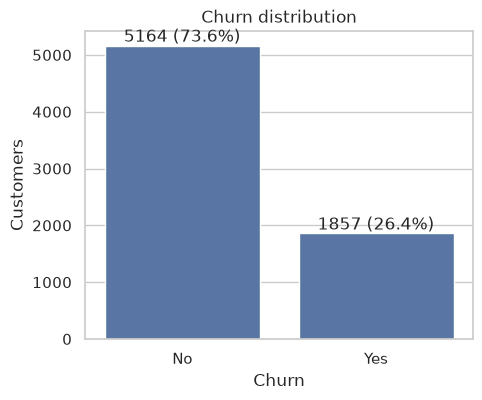

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df[TARGET].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
ax.set(title="Churn distribution", xlabel="Churn", ylabel="Customers")
plt.show()

## 4. Numeric distributions
Histograms of the numeric variables, split by churn.

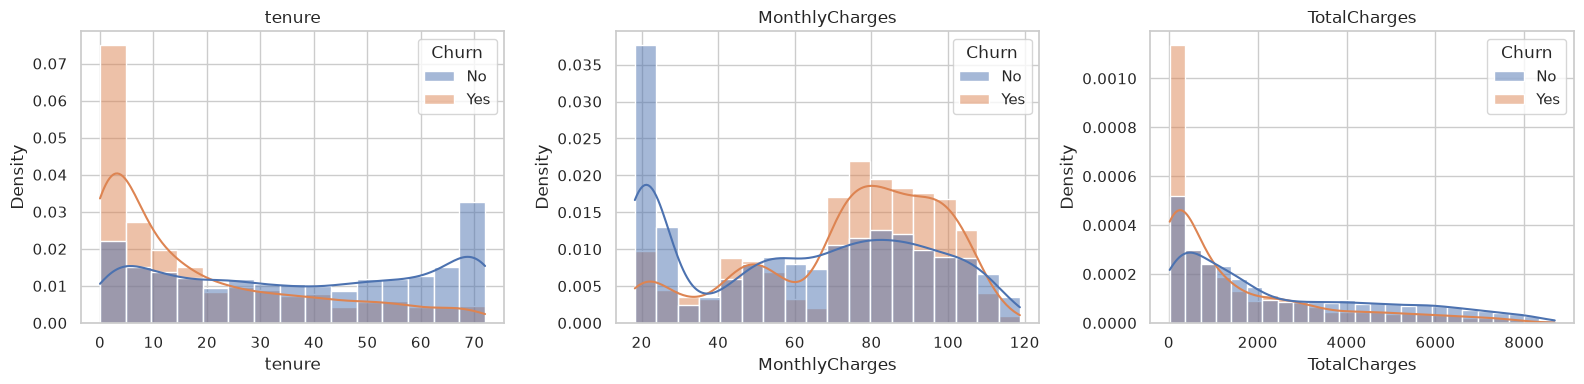

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, RAW_NUMERIC):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
df.groupby(TARGET)[RAW_NUMERIC + ["SeniorCitizen"]].mean().round(2)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
Churn,,,,
No,37.64,61.34,2560.26,0.13
Yes,18.09,74.60,1541.38,0.26


**Observations**
- `tenure` is bimodal (many brand-new customers and many customers at ~72 months).
  Churners are concentrated in the first months.
- Churners pay **higher monthly charges** on average.
- `TotalCharges` is strongly right-skewed (it is roughly `tenure × MonthlyCharges`);
  churners have lower totals because they leave early.
- Senior citizens churn more often.

## 5. Outliers
We use the **IQR rule** (values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`) and boxplots.

In [12]:
def iqr_outliers(s: pd.Series) -> int:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({col: {"outliers (IQR)": iqr_outliers(df[col].dropna())} for col in RAW_NUMERIC}).T

,outliers (IQR)
tenure,0
MonthlyCharges,0
TotalCharges,0


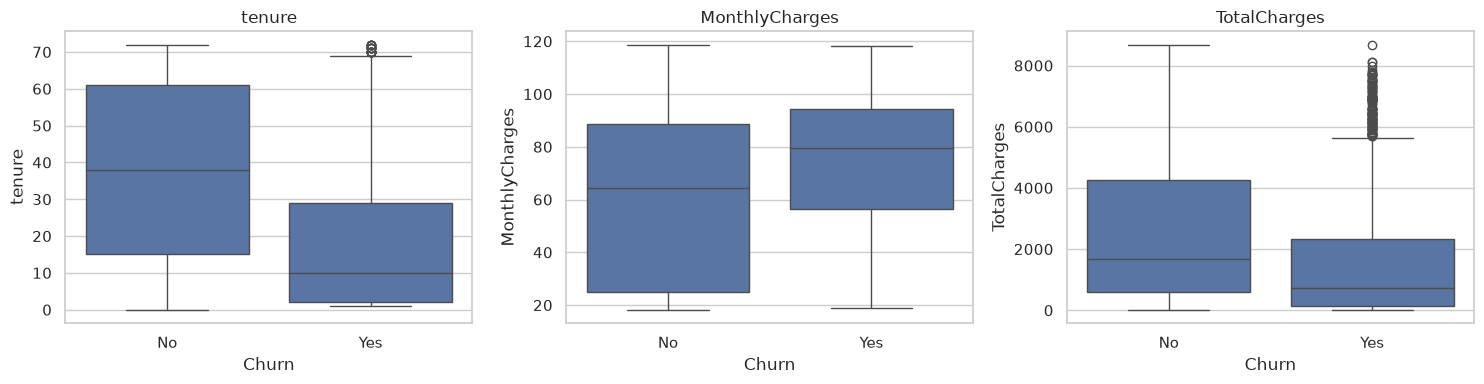

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, RAW_NUMERIC):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

No numeric column has IQR outliers: the values are within realistic business ranges
(0–72 months, ~18–119 per month). The skewness of `TotalCharges` is natural, not an
error, so **no outlier removal is needed**; standardization will put all numeric
features on the same scale.

## 6. Categorical variables vs churn
Churn rate per category for every categorical variable (dashed line = global churn rate).

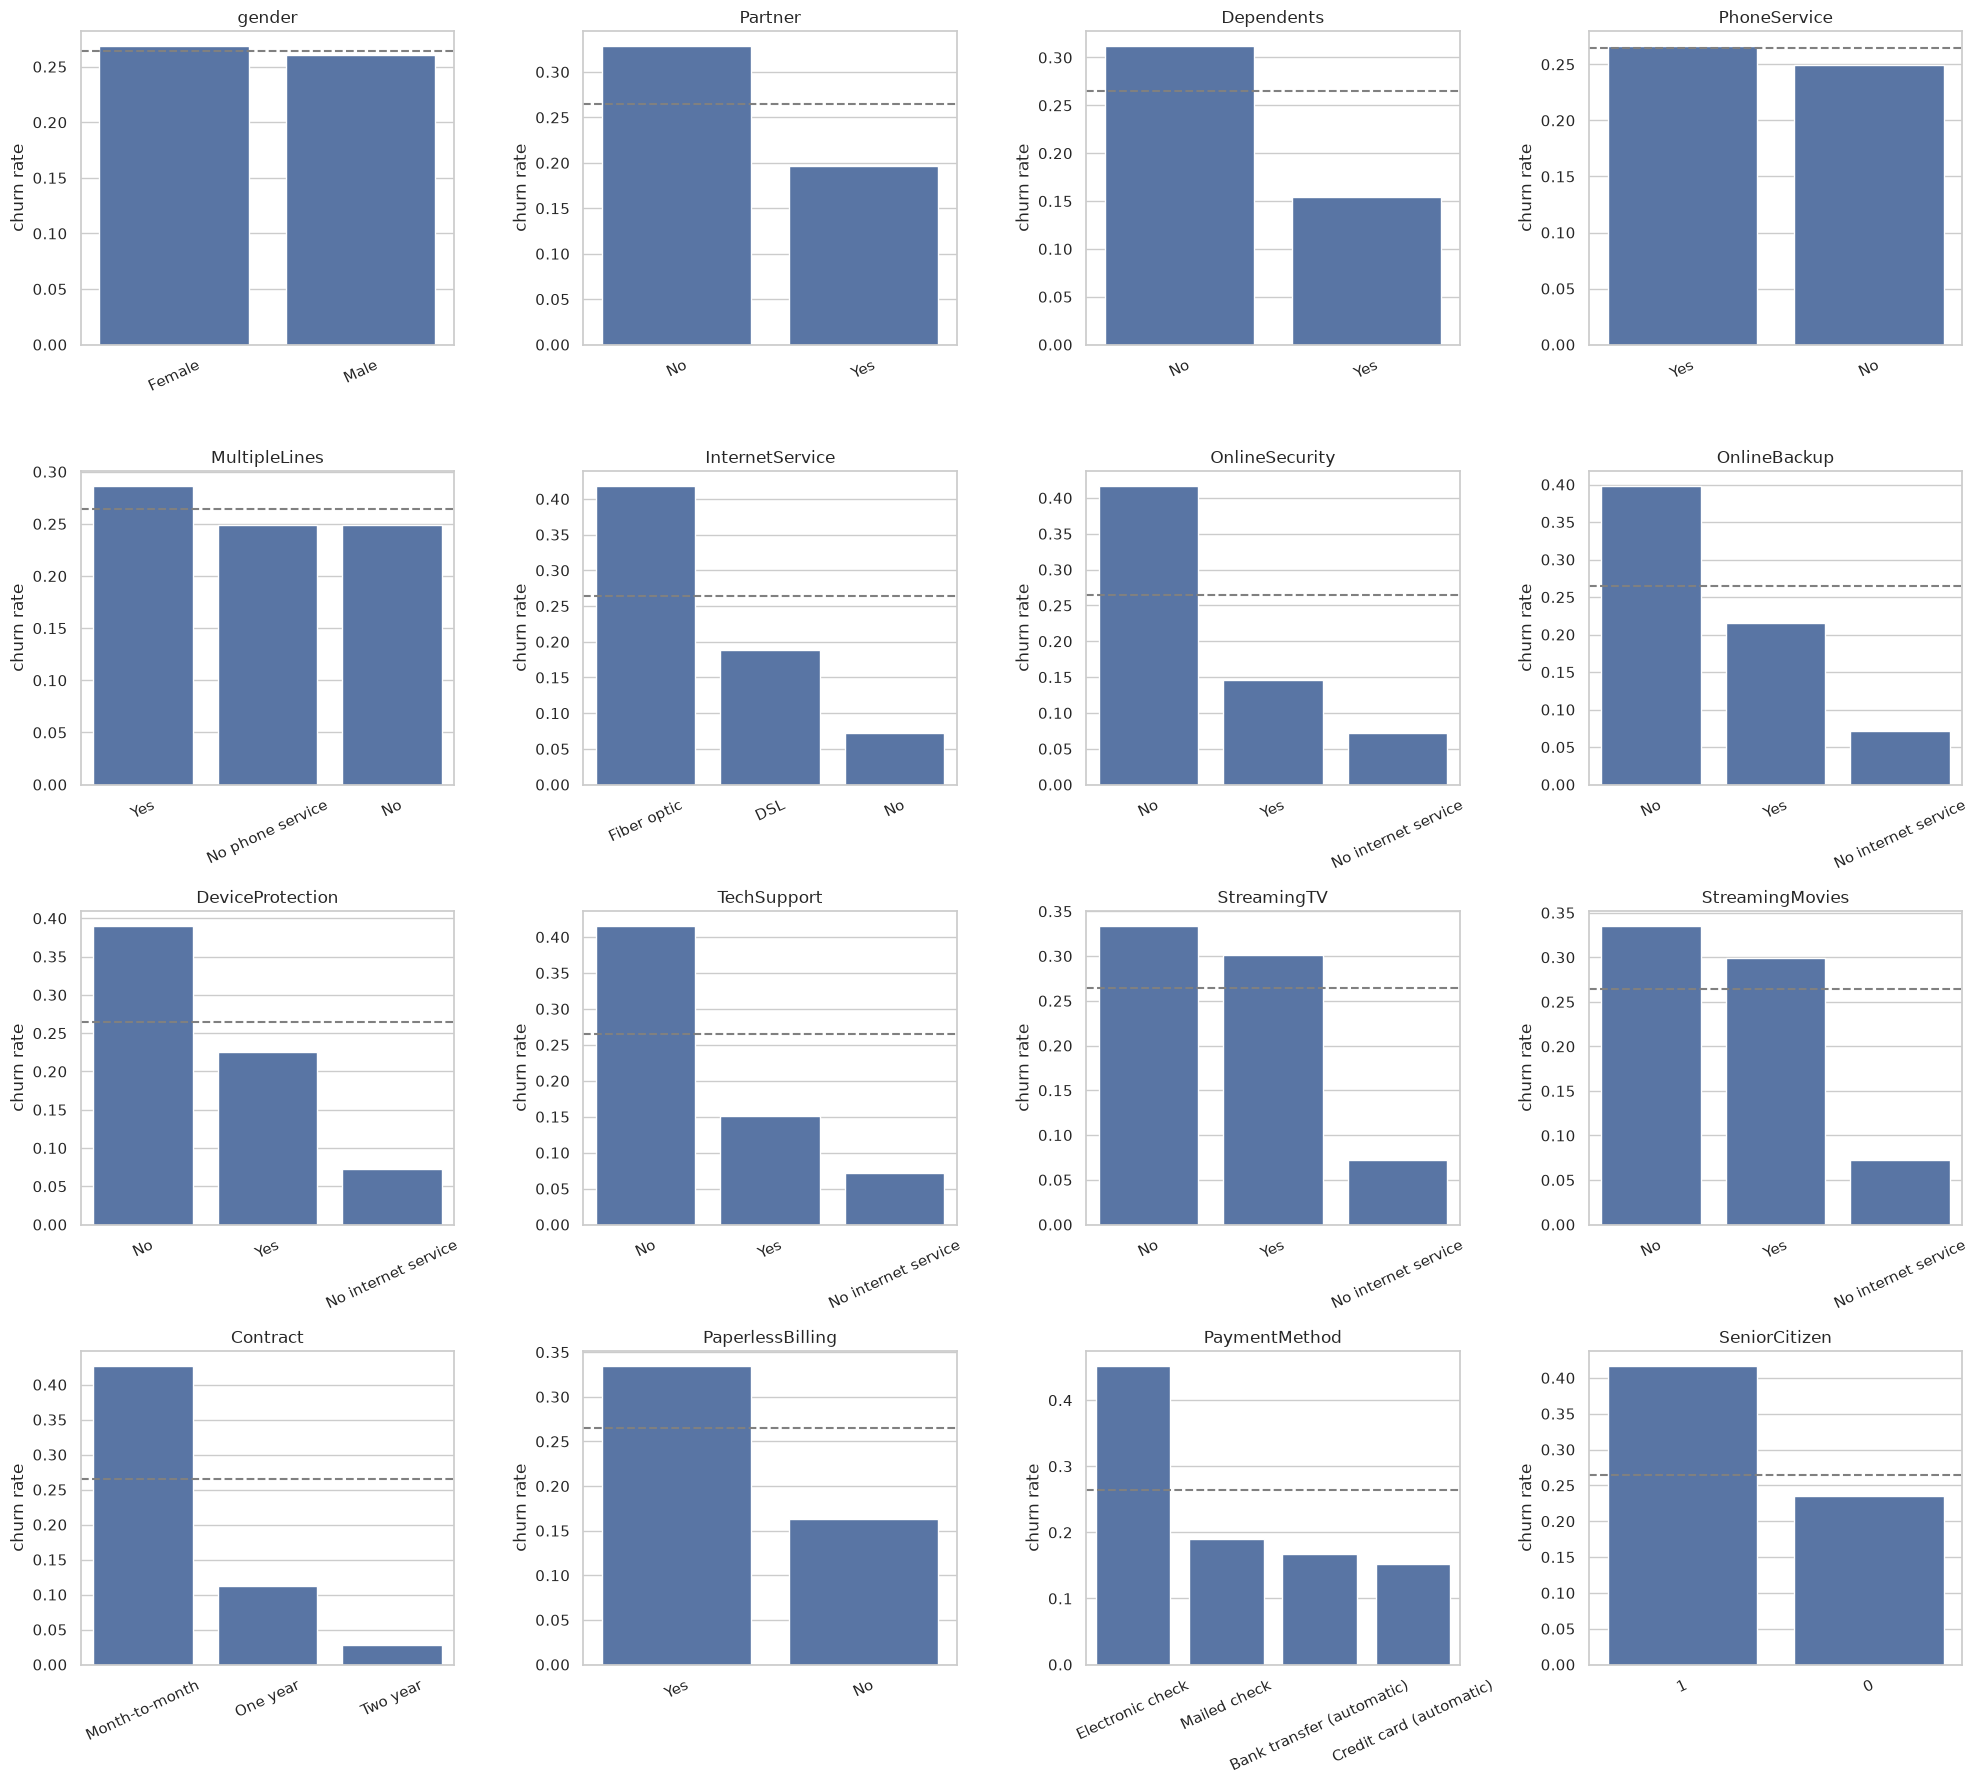

In [14]:
churn_flag = (df[TARGET] == "Yes").astype(int)
global_rate = churn_flag.mean()

cols = RAW_CATEGORICAL + ["SeniorCitizen"]
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, col in zip(axes.ravel(), cols):
    rate = churn_flag.groupby(df[col]).mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(global_rate, ls="--", color="grey")
    ax.set(title=col, ylabel="churn rate", xlabel="")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**Observations**
- **Contract** is the strongest driver: month-to-month customers churn far more than
  one/two-year contracts.
- **Fiber optic** internet users churn more than DSL users; customers without internet churn little.
- Customers **without** `OnlineSecurity` / `TechSupport` / `OnlineBackup` churn more.
- **Electronic check** payment and **paperless billing** are associated with higher churn.
- Customers without partner / dependents churn more.
- `gender` and `PhoneService` have almost no effect.

## 7. Correlations
### 7.1 Numeric variables

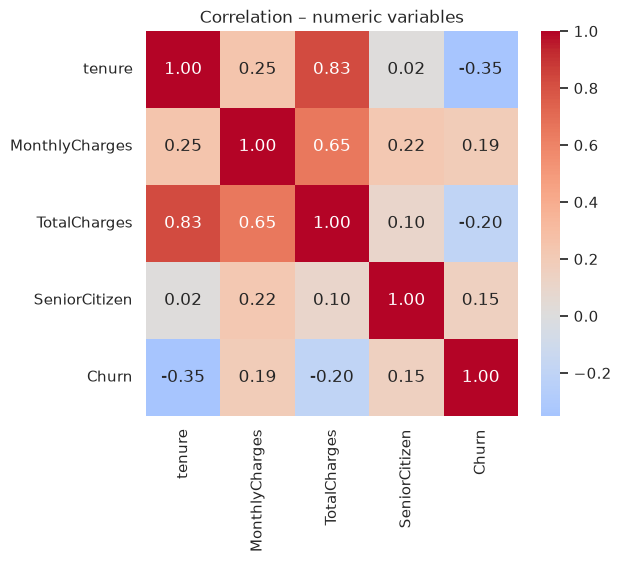

In [15]:
num_corr = df[RAW_NUMERIC + ["SeniorCitizen"]].assign(Churn=churn_flag).corr()
plt.figure(figsize=(6, 5))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation – numeric variables")
plt.show()

`TotalCharges` is highly correlated with `tenure` (≈0.83) — expected since it is
accumulated over time. `tenure` is negatively correlated with churn, `MonthlyCharges`
positively.

### 7.2 All variables (one-hot encoded) vs churn

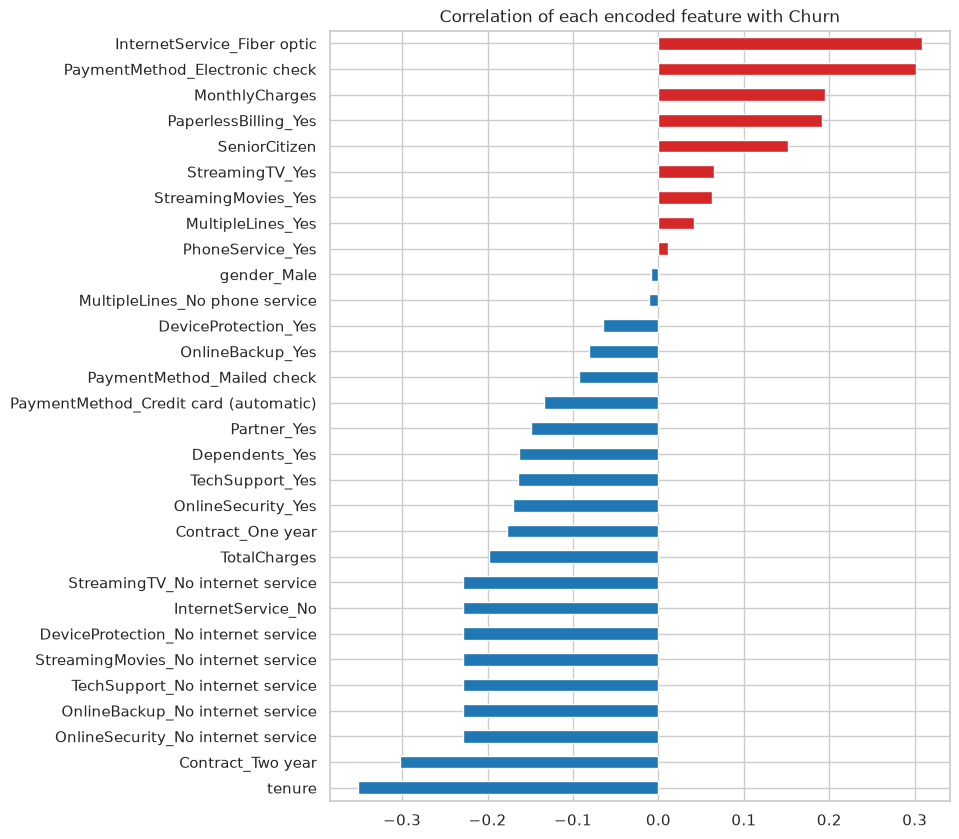

In [16]:
encoded = pd.get_dummies(df.drop(columns=[ID_COLUMN, TARGET]), drop_first=True, dtype=int)
corr_target = encoded.corrwith(churn_flag).sort_values()
plt.figure(figsize=(8, 10))
corr_target.plot.barh(color=np.where(corr_target > 0, "tab:red", "tab:blue"))
plt.title("Correlation of each encoded feature with Churn")
plt.show()

## 8. Feature engineering
New features built from domain knowledge (function `add_features` below).
They are computed **row by row**, without any statistic learned from the data, so they
cannot leak information between train and test.

| Feature | Definition | Intuition |
| --- | --- | --- |
| `num_services` | number of subscribed services (phone, internet, options…) | more services → more engaged customer |
| `avg_monthly_spend` | `TotalCharges / tenure` | historical average bill vs current bill |
| `charges_per_service` | `MonthlyCharges / num_services` | price paid per service (perceived value) |
| `is_month_to_month` | contract is month-to-month | no commitment → easy to leave |
| `auto_payment` | bank transfer / credit card automatic payment | low-friction payment, more loyal |
| `has_family` | has a partner or dependents | household customers are more stable |
| `is_new_customer` | `tenure ≤ 6` months | the first months are the riskiest |
| `tenure_group` | tenure binned (0-12, 13-24, 25-48, 49-60, 61-72) | non-linear effect of tenure |

In [17]:
SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def add_features(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    # number of services: Yes/No options + internet itself
    df["num_services"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
    # lifetime average bill (new customers: current bill)
    df["avg_monthly_spend"] = np.where(df["tenure"] > 0,
                                       df["TotalCharges"] / df["tenure"].replace(0, np.nan),
                                       df["MonthlyCharges"])
    df["charges_per_service"] = df["MonthlyCharges"] / df["num_services"].clip(lower=1)
    df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)
    df["auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                                labels=["0-12", "13-24", "25-48", "49-60", "61-72"]).astype(str)
    return df


df_fe = add_features(df)
new_cols = [c for c in df_fe.columns if c not in df.columns]
df_fe[new_cols].head()

,num_services,avg_monthly_spend,charges_per_service,is_month_to_month,auto_payment,has_family,is_new_customer,tenure_group
0,2,29.850000,14.9250,1,0,1,1,0-12
1,4,55.573529,14.2375,0,0,0,0,25-48
2,4,54.075000,13.4625,1,0,0,1,0-12
3,4,40.905556,10.5750,0,1,0,0,25-48
4,2,75.825000,35.3500,1,0,0,1,0-12


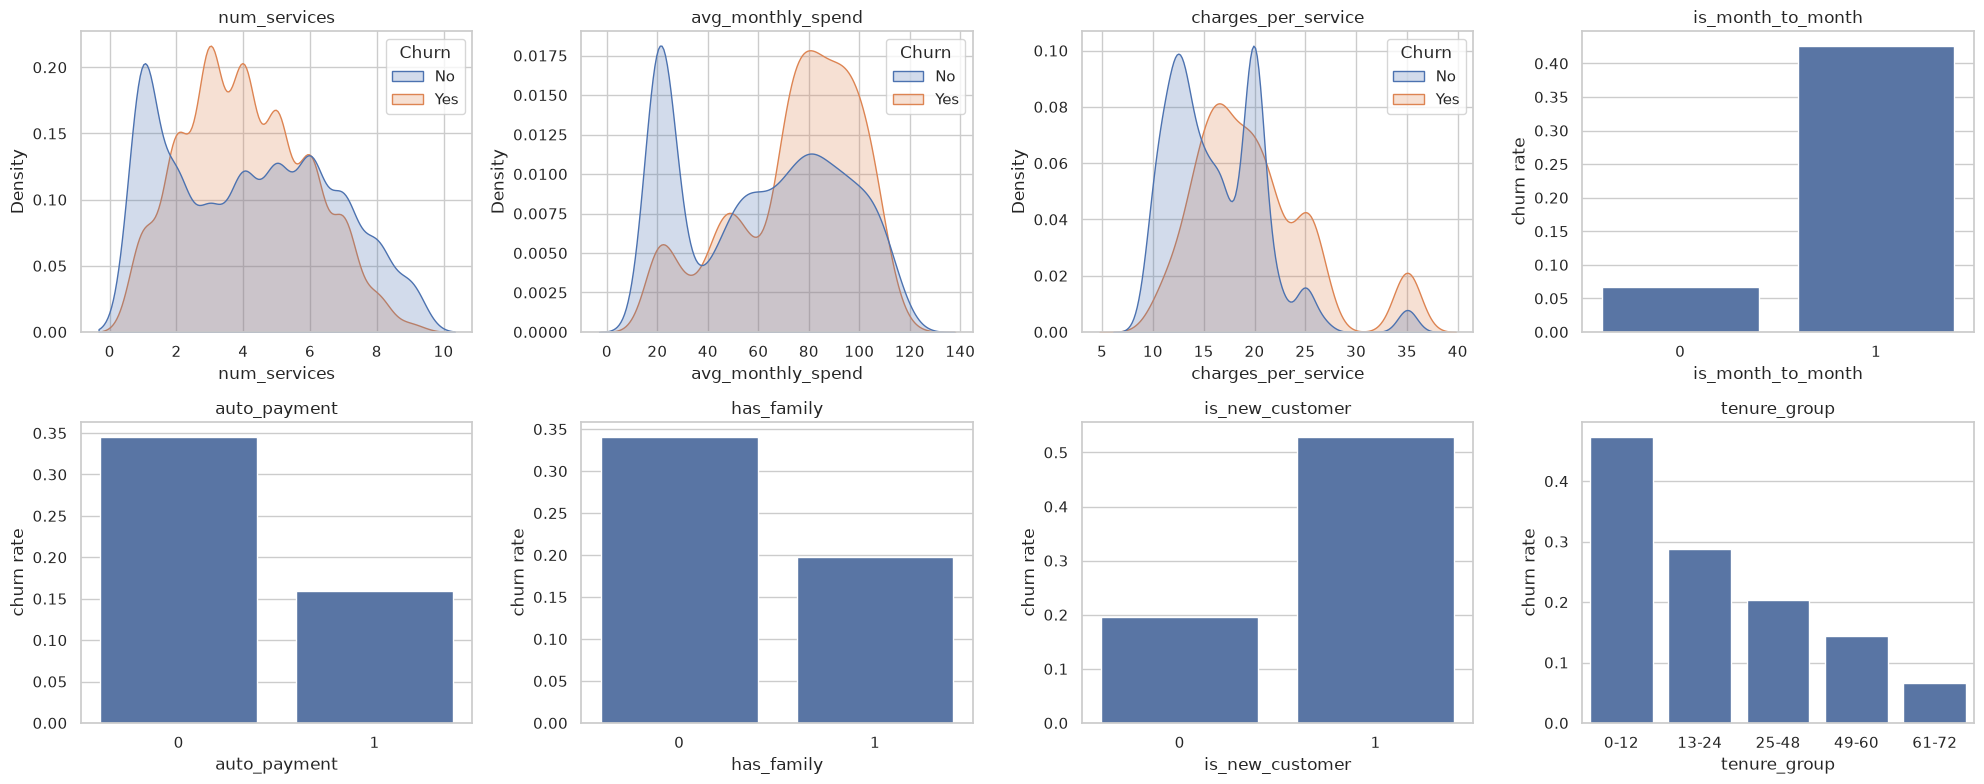

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), new_cols):
    if df_fe[col].nunique() <= 6:
        rate = churn_flag.groupby(df_fe[col]).mean()
        sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
        ax.set_ylabel("churn rate")
    else:
        sns.kdeplot(data=df_fe, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [19]:
df_fe[new_cols].select_dtypes("number").corrwith(churn_flag).sort_values().to_frame("corr with churn")

,corr with churn
auto_payment,-0.208956
has_family,-0.161418
num_services,-0.017576
avg_monthly_spend,0.193674
charges_per_service,0.288649
is_new_customer,0.307300
is_month_to_month,0.404884


The engineered features carry a clear signal: `is_month_to_month` and `is_new_customer`
are strongly linked to churn, while `auto_payment`, `has_family` and long tenure groups
are linked to loyalty. Their real contribution to the model is measured in notebook 05.

## 9. Encoding & scaling
The preprocessing is a scikit-learn `ColumnTransformer`:
- **numeric** → median imputation + `StandardScaler` (mean 0, std 1)
- **binary** (0/1) → kept as is
- **categorical** → most-frequent imputation + `OneHotEncoder` (one column per category,
  a single column for Yes/No variables)

⚠️ **Data leakage:** the imputer and scaler learn statistics (median, mean, std). They
must be **fitted on the training set only** and then applied to the test set. That's why
the split is done first, and why in the next notebooks the preprocessing lives *inside*
the model pipeline (so it is refitted on each cross-validation fold).

In [20]:
NUMERIC_FEATURES = RAW_NUMERIC + ["num_services", "avg_monthly_spend", "charges_per_service"]
BINARY_FEATURES = RAW_BINARY + ["is_month_to_month", "auto_payment", "has_family", "is_new_customer"]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["tenure_group"]


def make_preprocessor(numeric=NUMERIC_FEATURES, binary=BINARY_FEATURES, categorical=CATEGORICAL_FEATURES):
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                          sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric),
                              ("bin", "passthrough", binary),
                              ("cat", categorical_pipe, categorical)],
                             verbose_feature_names_out=False)

In [21]:
X = df_fe.drop(columns=[ID_COLUMN, TARGET])
y = churn_flag

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = make_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)   # fit on train only
X_test_t = preprocessor.transform(X_test)         # apply to test

feature_names = preprocessor.get_feature_names_out()
print("Train:", X_train_t.shape, " Test:", X_test_t.shape)
print(f"{len(NUMERIC_FEATURES)} numeric + {len(BINARY_FEATURES)} binary + "
      f"{len(CATEGORICAL_FEATURES)} categorical -> {len(feature_names)} model features")

Train: (5616, 52)  Test: (1405, 52)
6 numeric + 5 binary + 16 categorical -> 52 model features


In [22]:
X_train_df = pd.DataFrame(X_train_t, columns=feature_names)
X_train_df[NUMERIC_FEATURES].describe().loc[["mean", "std"]].round(3)

,tenure,MonthlyCharges,TotalCharges,num_services,avg_monthly_spend,charges_per_service
mean,0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


Numeric features are now centred (mean ≈ 0) with unit variance on the training set.

In [23]:
X_train_df.head()

,tenure,MonthlyCharges,TotalCharges,num_services,avg_monthly_spend,charges_per_service,SeniorCitizen,is_month_to_month,auto_payment,has_family,is_new_customer,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,...,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12,tenure_group_13-24,tenure_group_25-48,tenure_group_49-60,tenure_group_61-72
0,-1.241331,0.193165,-0.946349,-0.931930,0.179602,3.369608,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.711078,0.647355,-0.435345,0.364080,0.726230,-0.077571,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.409933,0.820380,1.794547,0.364080,1.000568,0.116426,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-1.118965,0.023467,-0.858745,0.364080,0.101054,-0.777080,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-0.262403,-1.483847,-0.783388,-1.363933,-1.500270,0.562246,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


## 10. Save the prepared dataset
We export the **cleaned + engineered** (but not scaled) dataset for reference / reuse.
The other notebooks do not depend on it: each one rebuilds what it needs from the raw CSV.
Scaling/encoding is not saved because it must be refitted on the training data.

In [24]:
PROCESSED_DATA.parent.mkdir(parents=True, exist_ok=True)
df_fe.to_csv(PROCESSED_DATA, index=False)
print("Saved ->", PROCESSED_DATA.relative_to(ROOT), df_fe.shape)

Saved -> data/processed/telco_clean.csv (7021, 29)


## Summary
- 7043 customers, 21 columns; 11 missing `TotalCharges` (tenure 0) → imputed in the pipeline;
  22 duplicated customer profiles removed → 7021 rows.
- No abnormal outliers in the numeric variables.
- Imbalanced target (~26.5 % churn).
- Main churn drivers: short tenure, month-to-month contract, fiber optic, no security /
  tech support, electronic check, high monthly charges.
- 8 engineered features added; preprocessing = impute + scale + one-hot, always fitted on
  training data only.